In [13]:
import pandas as pd
import numpy as np
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

In [14]:
df = pd.read_csv("Downloads/ACME-HappinessSurvey2020.csv") 
print(df.head())
print(df.shape)

   Y  X1  X2  X3  X4  X5  X6
0  0   3   3   3   4   2   4
1  0   3   2   3   5   4   3
2  1   5   3   3   3   3   5
3  0   5   4   3   3   3   5
4  0   5   4   3   3   3   5
(126, 7)


Classifiers

In [15]:
# df: columns X1..X6 (1-5), Y (0/1)
features = ['X1','X2','X3','X4','X5','X6']
X = df[features]
y = df['Y']

In [16]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

In [17]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [18]:

model = RandomForestClassifier(
    random_state=42
)

model.fit(X_train, y_train)

RandomForestClassifier(random_state=42)

In [20]:
from sklearn.model_selection import StratifiedKFold

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [23]:
#Random Forest
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score
import numpy as np

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

rf = RandomForestClassifier(
    n_estimators=500,
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=1,
    random_state=42
)

rf_scores = cross_val_score(
    rf,
    X,
    y,
    cv=cv,
    scoring='accuracy'
)

print("Random Forest CV Scores:", rf_scores)
print("Mean Accuracy:", np.mean(rf_scores))

Random Forest CV Scores: [0.65384615 0.64       0.6        0.6        0.4       ]
Mean Accuracy: 0.5787692307692308


In [24]:
#extra trees classifier
from sklearn.ensemble import ExtraTreesClassifier

et = ExtraTreesClassifier(
    n_estimators=500,
    random_state=42
)

et_scores = cross_val_score(
    et,
    X,
    y,
    cv=cv,
    scoring='accuracy'
)

print("Extra Trees CV Scores:", et_scores)
print("Mean Accuracy:", np.mean(et_scores))

Extra Trees CV Scores: [0.65384615 0.64       0.6        0.56       0.56      ]
Mean Accuracy: 0.6027692307692308


Features to remove for best accuracy

In [29]:
model.fit(X, y)

import pandas as pd

importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': model.feature_importances_
}).sort_values('Importance', ascending=False)

print(importance)

  Feature  Importance
2      X3    0.197599
1      X2    0.177116
4      X5    0.175312
0      X1    0.172084
3      X4    0.147127
5      X6    0.130761


In [35]:
for combo in combinations(features, 3):

    X_temp = X.drop(columns=list(combo))

    score = cross_val_score(
        lr,
        X_temp,
        y,
        cv=cv,
        scoring='accuracy'
    ).mean()

    print(f"Removed {combo}: {score:.4f}")

Removed ('X1', 'X2', 'X3'): 0.5557
Removed ('X1', 'X2', 'X4'): 0.5317
Removed ('X1', 'X2', 'X5'): 0.5554
Removed ('X1', 'X2', 'X6'): 0.5957
Removed ('X1', 'X3', 'X4'): 0.5314
Removed ('X1', 'X3', 'X5'): 0.5551
Removed ('X1', 'X3', 'X6'): 0.5874
Removed ('X1', 'X4', 'X5'): 0.6114
Removed ('X1', 'X4', 'X6'): 0.5480
Removed ('X1', 'X5', 'X6'): 0.5637
Removed ('X2', 'X3', 'X4'): 0.5871
Removed ('X2', 'X3', 'X5'): 0.5945
Removed ('X2', 'X3', 'X6'): 0.5791
Removed ('X2', 'X4', 'X5'): 0.5714
Removed ('X2', 'X4', 'X6'): 0.5711
Removed ('X2', 'X5', 'X6'): 0.5951
Removed ('X3', 'X4', 'X5'): 0.6025
Removed ('X3', 'X4', 'X6'): 0.5871
Removed ('X3', 'X5', 'X6'): 0.6025
Removed ('X4', 'X5', 'X6'): 0.5711


In [36]:
from itertools import combinations

features = ['X1','X2','X3','X4','X5','X6']

best_score = 0
best_combo = None

for r in range(1, 4):  # test removing 1, 2, or 3 features

    for combo in combinations(features, r):

        X_temp = X.drop(columns=list(combo))

        score = cross_val_score(
            lr,
            X_temp,
            y,
            cv=cv,
            scoring='accuracy'
        ).mean()

        if score > best_score:
            best_score = score
            best_combo = combo

print("Best Features to Remove:", best_combo)
print("Best Accuracy:", best_score)

Best Features to Remove: ('X1', 'X4', 'X5')
Best Accuracy: 0.6113846153846154


In [37]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score
from itertools import combinations

rf = RandomForestClassifier(
    n_estimators=500,
    random_state=42
)

features = ['X1','X2','X3','X4','X5','X6']

best_score = 0
best_combo = None

for r in range(1, 4):  # test removing 1, 2, or 3 features

    for combo in combinations(features, r):

        X_temp = X.drop(columns=list(combo))

        score = cross_val_score(
            rf,
            X_temp,
            y,
            cv=cv,
            scoring='accuracy'
        ).mean()

        print(f"Removed {combo}: {score:.4f}")

        if score > best_score:
            best_score = score
            best_combo = combo

print("\nBest Features to Remove:", best_combo)
print("Best Accuracy:", best_score)

Removed ('X1',): 0.5545
Removed ('X2',): 0.6108
Removed ('X3',): 0.6188
Removed ('X4',): 0.6031
Removed ('X5',): 0.6508
Removed ('X6',): 0.6185
Removed ('X1', 'X2'): 0.5480
Removed ('X1', 'X3'): 0.5631
Removed ('X1', 'X4'): 0.5074
Removed ('X1', 'X5'): 0.5317
Removed ('X1', 'X6'): 0.5868
Removed ('X2', 'X3'): 0.6194
Removed ('X2', 'X4'): 0.6505
Removed ('X2', 'X5'): 0.6742
Removed ('X2', 'X6'): 0.6031
Removed ('X3', 'X4'): 0.5877
Removed ('X3', 'X5'): 0.6117
Removed ('X3', 'X6'): 0.5948
Removed ('X4', 'X5'): 0.6274
Removed ('X4', 'X6'): 0.6265
Removed ('X5', 'X6'): 0.6105
Removed ('X1', 'X2', 'X3'): 0.5240
Removed ('X1', 'X2', 'X4'): 0.5080
Removed ('X1', 'X2', 'X5'): 0.5391
Removed ('X1', 'X2', 'X6'): 0.5800
Removed ('X1', 'X3', 'X4'): 0.5871
Removed ('X1', 'X3', 'X5'): 0.4766
Removed ('X1', 'X3', 'X6'): 0.6351
Removed ('X1', 'X4', 'X5'): 0.4843
Removed ('X1', 'X4', 'X6'): 0.5717
Removed ('X1', 'X5', 'X6'): 0.5391
Removed ('X2', 'X3', 'X4'): 0.6508
Removed ('X2', 'X3', 'X5'): 0.6197
R

In [38]:
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import cross_val_score
from itertools import combinations

gb = GradientBoostingClassifier(
    random_state=42
)

features = ['X1', 'X2', 'X3', 'X4', 'X5', 'X6']

best_score = 0
best_combo = None

for r in range(1, 4):  # remove 1, 2, or 3 features

    for combo in combinations(features, r):

        X_temp = X.drop(columns=list(combo))

        score = cross_val_score(
            gb,
            X_temp,
            y,
            cv=cv,
            scoring='accuracy'
        ).mean()

        print(f"Removed {combo}: {score:.4f}")

        if score > best_score:
            best_score = score
            best_combo = combo

print("\nBest Features to Remove:", best_combo)
print("Best Accuracy:", best_score)

Removed ('X1',): 0.5474
Removed ('X2',): 0.6582
Removed ('X3',): 0.6505
Removed ('X4',): 0.6265
Removed ('X5',): 0.6028
Removed ('X6',): 0.6108
Removed ('X1', 'X2'): 0.5240
Removed ('X1', 'X3'): 0.5865
Removed ('X1', 'X4'): 0.5554
Removed ('X1', 'X5'): 0.5560
Removed ('X1', 'X6'): 0.5942
Removed ('X2', 'X3'): 0.6105
Removed ('X2', 'X4'): 0.6582
Removed ('X2', 'X5'): 0.6578
Removed ('X2', 'X6'): 0.5951
Removed ('X3', 'X4'): 0.6342
Removed ('X3', 'X5'): 0.5883
Removed ('X3', 'X6'): 0.6345
Removed ('X4', 'X5'): 0.6351
Removed ('X4', 'X6'): 0.6425
Removed ('X5', 'X6'): 0.6102
Removed ('X1', 'X2', 'X3'): 0.5394
Removed ('X1', 'X2', 'X4'): 0.5080
Removed ('X1', 'X2', 'X5'): 0.5631
Removed ('X1', 'X2', 'X6'): 0.5640
Removed ('X1', 'X3', 'X4'): 0.5791
Removed ('X1', 'X3', 'X5'): 0.4689
Removed ('X1', 'X3', 'X6'): 0.6182
Removed ('X1', 'X4', 'X5'): 0.4763
Removed ('X1', 'X4', 'X6'): 0.5154
Removed ('X1', 'X5', 'X6'): 0.5311
Removed ('X2', 'X3', 'X4'): 0.6505
Removed ('X2', 'X3', 'X5'): 0.5723
R

In [40]:
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import cross_val_score

gb = GradientBoostingClassifier(
    random_state=42
)

X_no_x2_x5 = X.drop(columns=['X2', 'X5'])

scores = cross_val_score(
    gb,
    X_no_x2_x5,
    y,
    cv=cv,
    scoring='accuracy'
)

print("CV Scores:", scores)
print("Mean Accuracy:", scores.mean())

CV Scores: [0.76923077 0.72       0.6        0.56       0.64      ]
Mean Accuracy: 0.657846153846154


In [45]:
from sklearn.ensemble import ExtraTreesClassifier

et = ExtraTreesClassifier(
    n_estimators=500,
    random_state=42
)

scores = cross_val_score(
    et,
    X_reduced,
    y,
    cv=cv,
    scoring='accuracy'
)

print("Extra Trees:", scores.mean())

Extra Trees: 0.713846153846154


In [61]:
et = ExtraTreesClassifier(
    n_estimators=5000,
    random_state=42
)

scores = cross_val_score(
    et,
    X_reduced,
    y,
    cv=cv,
    scoring='accuracy'
)

print("Extra Trees:", scores.mean())

Extra Trees: 0.713846153846154


In [63]:
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.model_selection import cross_val_score

best_score = 0
best_seed = None

for seed in range(0, 101):

    et = ExtraTreesClassifier(
        n_estimators=500,
        random_state=seed
    )

    score = cross_val_score(
        et,
        X_reduced,
        y,
        cv=cv,
        scoring='accuracy'
    ).mean()

    if score > best_score:
        best_score = score
        best_seed = seed

    print(f"Seed {seed}: {score:.4f}")

print("\nBest Seed:", best_seed)
print("Best Accuracy:", best_score)

Seed 0: 0.7138
Seed 1: 0.7218
Seed 2: 0.7058
Seed 3: 0.7138
Seed 4: 0.7138
Seed 5: 0.7138
Seed 6: 0.7138
Seed 7: 0.7058
Seed 8: 0.7138
Seed 9: 0.7218
Seed 10: 0.7218
Seed 11: 0.7218
Seed 12: 0.7138
Seed 13: 0.7138
Seed 14: 0.7218
Seed 15: 0.7138
Seed 16: 0.7218
Seed 17: 0.7058
Seed 18: 0.7295
Seed 19: 0.7138
Seed 20: 0.7138
Seed 21: 0.7218
Seed 22: 0.7138
Seed 23: 0.6978
Seed 24: 0.7138
Seed 25: 0.7138
Seed 26: 0.7138
Seed 27: 0.7138
Seed 28: 0.7138
Seed 29: 0.7218
Seed 30: 0.7218
Seed 31: 0.7138
Seed 32: 0.7058
Seed 33: 0.7138
Seed 34: 0.7058
Seed 35: 0.7138
Seed 36: 0.7138
Seed 37: 0.7218
Seed 38: 0.7298
Seed 39: 0.7138
Seed 40: 0.7138
Seed 41: 0.7138
Seed 42: 0.7138
Seed 43: 0.7218
Seed 44: 0.7138
Seed 45: 0.7218
Seed 46: 0.7138
Seed 47: 0.7218
Seed 48: 0.7218
Seed 49: 0.7138
Seed 50: 0.7138
Seed 51: 0.7058
Seed 52: 0.7058
Seed 53: 0.7218
Seed 54: 0.7138
Seed 55: 0.7138
Seed 56: 0.7058
Seed 57: 0.7218
Seed 58: 0.7218
Seed 59: 0.7138
Seed 60: 0.7138
Seed 61: 0.7218
Seed 62: 0.7218
Se

The best accuracy given was a 0.729, rounding up to 0.73 using the Extra Trees Classifier. This was found the best removing the columns X2 and X5 which are contents of my order was as I expected and I am satisfied with my courier

Correlation between the features

In [33]:
corr = df.corr(numeric_only=True)
corr

,Y,X1,X2,X3,X4,X5,X6
Y,1.000000,0.280160,-0.024274,0.150838,0.064415,0.224522,0.167669
X1,0.280160,1.000000,0.059797,0.283358,0.087541,0.432772,0.411873
X2,-0.024274,0.059797,1.000000,0.184129,0.114838,0.039996,-0.062205
X3,0.150838,0.283358,0.184129,1.000000,0.302618,0.358397,0.203750
X4,0.064415,0.087541,0.114838,0.302618,1.000000,0.293115,0.215888
X5,0.224522,0.432772,0.039996,0.358397,0.293115,1.000000,0.320195
X6,0.167669,0.411873,-0.062205,0.203750,0.215888,0.320195,1.000000


In [34]:
from sklearn.model_selection import train_test_split

X = df.drop('Y', axis=1)
y = df['Y']

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [35]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [37]:
from sklearn.tree import DecisionTreeClassifier

dt = DecisionTreeClassifier(
    max_depth=5,
    random_state=42
)

dt.fit(X_train, y_train)

pred_dt = dt.predict(X_test)

print("Accuracy:", accuracy_score(y_test, pred_dt))

Accuracy: 0.7692307692307693


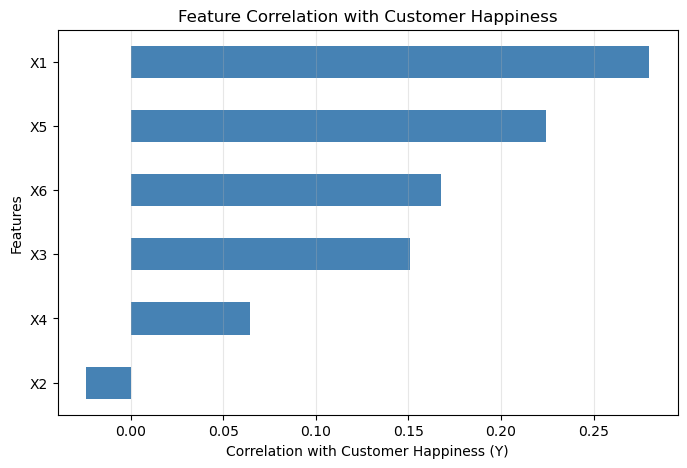

In [40]:
corr_with_y = df.corr()['Y'].drop('Y').sort_values()

plt.figure(figsize=(8,5))
corr_with_y.plot(kind='barh', color='steelblue')

plt.xlabel('Correlation with Customer Happiness (Y)')
plt.ylabel('Features')
plt.title('Feature Correlation with Customer Happiness')
plt.grid(axis='x', alpha=0.3)

plt.show()


The best correlation between features was X1 and X5, respectively my order was delivered on time and I am satisfied with my courier. Using decision trees classifier, I got the best results of 77% accuracy. 

In [62]:
et.fit(X, y)

importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': et.feature_importances_
})

print(
    importance.sort_values(
        'Importance',
        ascending=False
    )
)

  Feature  Importance
2      X3    0.189442
1      X2    0.186015
0      X1    0.181839
4      X5    0.157389
3      X4    0.153259
5      X6    0.132056


In [67]:
from sklearn.ensemble import ExtraTreesClassifier

et = ExtraTreesClassifier(
    n_estimators=500,
    random_state=42
)

et.fit(X, y)

ExtraTreesClassifier(n_estimators=500, random_state=42)

Visuals of feature importance

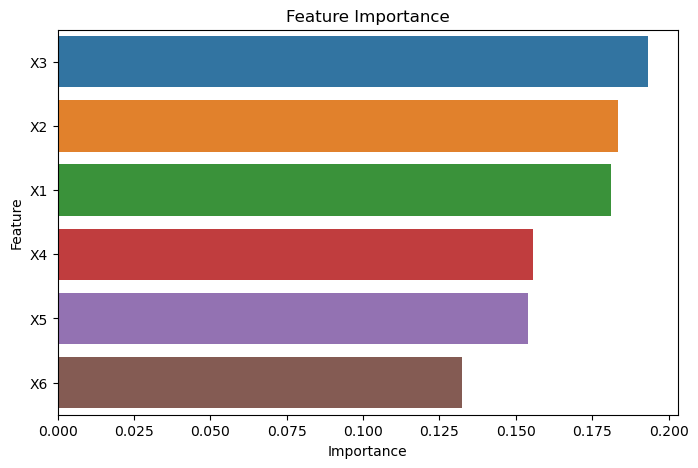

In [68]:
importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': et.feature_importances_
})

importance = importance.sort_values(
    'Importance',
    ascending=False
)

plt.figure(figsize=(8,5))

sns.barplot(
    data=importance,
    x='Importance',
    y='Feature'
)

plt.title('Feature Importance')
plt.show()

Important Features

In [73]:
rf.fit(X, y)

importance_df = (
    pd.DataFrame({
        'Feature': X.columns,
        'Importance': rf.feature_importances_
    })
    .sort_values('Importance', ascending=False)
)

print(importance_df)

  Feature  Importance
2      X3    0.186960
1      X2    0.180792
4      X5    0.180622
0      X1    0.163803
3      X4    0.155261
5      X6    0.132562


In [74]:
from sklearn.feature_selection import RFE
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=1000)

rfe = RFE(model, n_features_to_select=1)
rfe.fit(X, y)

feature_ranking = pd.DataFrame({
    'Feature': X.columns,
    'Rank': rfe.ranking_
}).sort_values('Rank')

print(feature_ranking)

  Feature  Rank
0      X1     1
4      X5     2
2      X3     3
5      X6     4
1      X2     5
3      X4     6


In [77]:
from itertools import combinations
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.model_selection import cross_val_score
import pandas as pd

results = []

for k in range(1, len(X.columns) + 1):

    for subset in combinations(X.columns, k):

        score = cross_val_score(
            ExtraTreesClassifier(
                n_estimators=500,
                random_state=42
            ),
            X[list(subset)],
            y,
            cv=cv,
            scoring='accuracy'
        ).mean()

        results.append({
            'Features': subset,
            'Num_Features': k,
            'Accuracy': score
        })

results_df = pd.DataFrame(results)

results_df.sort_values(
    'Accuracy',
    ascending=False
).head(20)

,Features,Num_Features,Accuracy
48,"(X1, X3, X4, X6)",4,0.713846
23,"(X1, X2, X5)",3,0.674154
10,"(X1, X6)",2,0.667077
27,"(X1, X3, X6)",3,0.666462
9,"(X1, X5)",2,0.650462
0,"(X1,)",1,0.650154
49,"(X1, X3, X5, X6)",4,0.642462
26,"(X1, X3, X5)",3,0.642462
30,"(X1, X5, X6)",3,0.642154
28,"(X1, X4, X5)",3,0.634769


The most important feature is everything I wanted to order, X3. Using correlation, the most important features were my order was delivered on time(X1) and I am satisfied with my courier(X5).